# DP3 – EDA (Exploratory Data Analysis) of the imputation results

We evaluate the 4 imputation methods from DP2 with **graphics** and **error measures**.

Important vocabulary:
- **Error** = imputed − true
- **Absolute error** = |imputed − true|  (unit: µg/m³)
- **Relative error** = |imputed − true| / true  (unit: %)
- **MAE** = mean absolute error,  **RMSE** = root mean squared error (punishes big errors more)
- **Reference:** to judge if an error is "big" we compare it with something, e.g. with the typical size of the values (the mean, the standard deviation).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Recompute the imputation (same code as DP2) so this notebook works on its own
df = pd.read_csv("../ex22PM10imputation.csv", sep=";", header=None, names=["pm10_missing", "pm10_true"])
s = df["pm10_missing"]
missing = s.isna()

imputed = {
    "mean":       s.fillna(s.mean()),
    "last value": s.ffill(),
    "linear":     s.interpolate(),
    "day before": s.fillna(s.shift(48)).fillna(s.ffill()),
}
true = df["pm10_true"][missing]

## (a) Which method is best?
We compute MAE and RMSE and show the **absolute errors as boxplots** (one box per method).

              MAE   RMSE  median abs. error
linear       1.36   2.48               0.65
last value   2.11   3.90               1.20
day before   9.85  13.30               7.80
mean        11.82  16.15               9.00


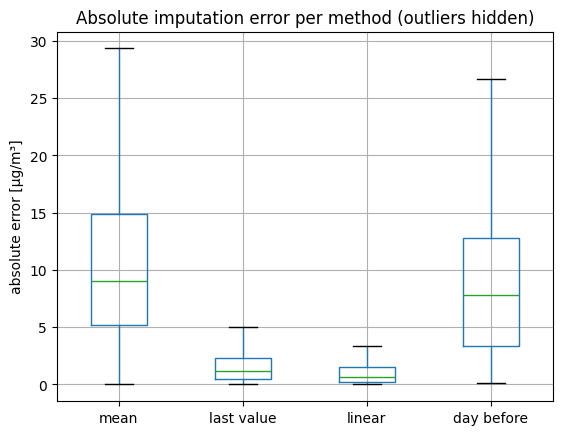

In [2]:
errors = pd.DataFrame({name: (imp[missing] - true).abs() for name, imp in imputed.items()})

summary = pd.DataFrame({
    "MAE":  errors.mean(),
    "RMSE": np.sqrt((errors ** 2).mean()),
    "median abs. error": errors.median(),
})
print(summary.round(2).sort_values("MAE"))

errors.boxplot(showfliers=False)
plt.ylabel("absolute error [µg/m³]")
plt.title("Absolute imputation error per method (outliers hidden)")
plt.show()

➡ **Winner: linear interpolation** (smallest MAE, RMSE and median), followed by "last value".
"Mean" is clearly the worst, "day before" is in between.

**Is this expected?** Yes. Air pollution changes slowly – the values 30 min before and 30 min after are very close to the missing one.
Interpolation uses *both* neighbours, so it is better than only using the previous one.
The "day before" idea would only be good if the series had a very strong daily pattern, but weather changes from day to day.

For (b)–(d) we use **linear interpolation**.

## (b) Is the imputation error high?
We need a **reference**: we compare the MAE with the typical level of PM10 values.

In [3]:
best = imputed["linear"]
err = best[missing] - true
abs_err = err.abs()
rel_err = abs_err / true * 100      # in percent

print("MAE linear interpolation  :", round(abs_err.mean(), 2), "µg/m³")
print("Mean PM10 value           :", round(df['pm10_true'].mean(), 2), "µg/m³")
print("Std. dev. of PM10         :", round(df['pm10_true'].std(), 2), "µg/m³")
print("Median relative error     :", round(rel_err.median(), 1), "%")
print("Imputed values / all values:", round(missing.mean() * 100, 2), "%")

print("\nMean of the series  true:", round(df['pm10_true'].mean(), 3), " imputed:", round(best.mean(), 3))
print("Std  of the series  true:", round(df['pm10_true'].std(), 3), " imputed:", round(best.std(), 3))

MAE linear interpolation  : 1.36 µg/m³
Mean PM10 value           : 20.87 µg/m³
Std. dev. of PM10         : 17.24 µg/m³
Median relative error     : 4.1 %
Imputed values / all values: 1.71 %

Mean of the series  true: 20.868  imputed: 20.864
Std  of the series  true: 17.243  imputed: 17.238


➡ The typical error (MAE ≈ 1.4 µg/m³, median relative error ≈ 4 %) is **small** compared to the values (mean ≈ 21, std ≈ 17).
Only 300 of 17 520 values (1.7 %) are imputed, and the mean and standard deviation of the series practically do not change.
→ We can expect that the imputation **does not harm** a following analysis.

## (c) Distribution of the imputation error
Two graphics:
1. **Histogram** of the relative error → shape of the distribution
2. **Empirical cumulative distribution function (ECDF)** → read probabilities directly, e.g. P(relative error > 5 %)

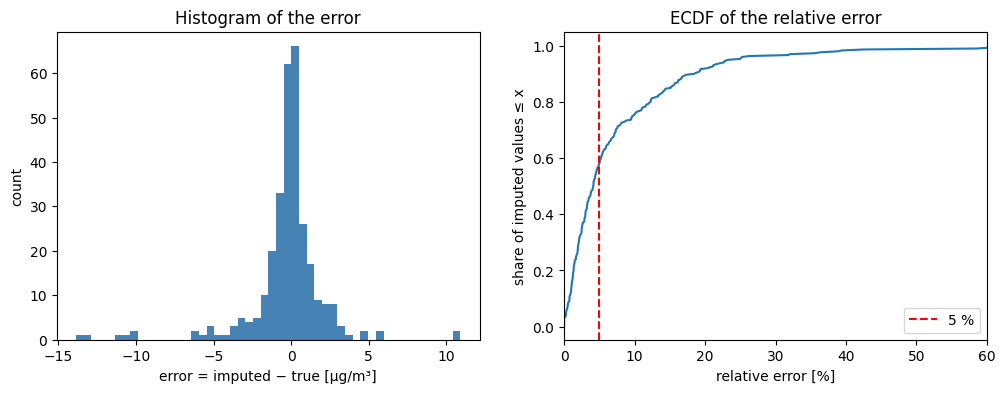

P(relative error > 5 %)  = 42.3 %
P(relative error > 10 %) = 24.7 %
P(relative error > 20 %) = 8.3 %


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(err, bins=50, color="steelblue")
ax[0].set_xlabel("error = imputed − true [µg/m³]")
ax[0].set_ylabel("count")
ax[0].set_title("Histogram of the error")

sorted_rel = np.sort(rel_err)
ecdf = np.arange(1, len(sorted_rel) + 1) / len(sorted_rel)
ax[1].plot(sorted_rel, ecdf)
ax[1].axvline(5, color="red", linestyle="--", label="5 %")
ax[1].set_xlim(0, 60)
ax[1].set_xlabel("relative error [%]")
ax[1].set_ylabel("share of imputed values ≤ x")
ax[1].set_title("ECDF of the relative error")
ax[1].legend()
plt.show()

p5 = (rel_err > 5).mean()
print("P(relative error > 5 %)  =", round(p5 * 100, 1), "%")
print("P(relative error > 10 %) =", round((rel_err > 10).mean() * 100, 1), "%")
print("P(relative error > 20 %) =", round((rel_err > 20).mean() * 100, 1), "%")

➡ The error is centred around **0** (no systematic over- or under-estimation) and most errors are small,
but the distribution has **long tails** (a few large errors where PM10 jumps quickly).
From the ECDF: **P(relative error > 5 %) ≈ 42 %**, P(> 10 %) ≈ 25 %, P(> 20 %) ≈ 8 %.
So almost half of the values miss by more than 5 % – but in absolute terms these errors are still small (median ≈ 1.75 µg/m³), and they tend to occur at lower PM10 levels, where a small denominator makes the relative error big.

## (d) Whole time series with the imputed points

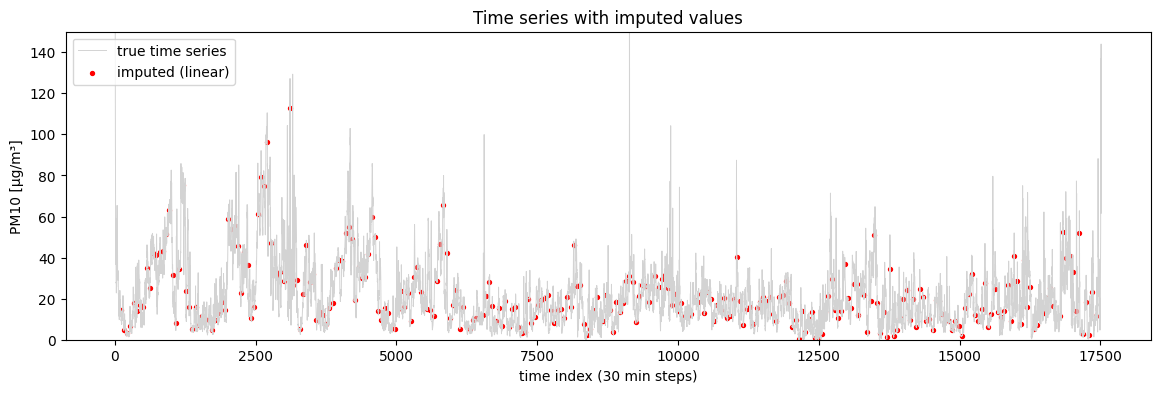

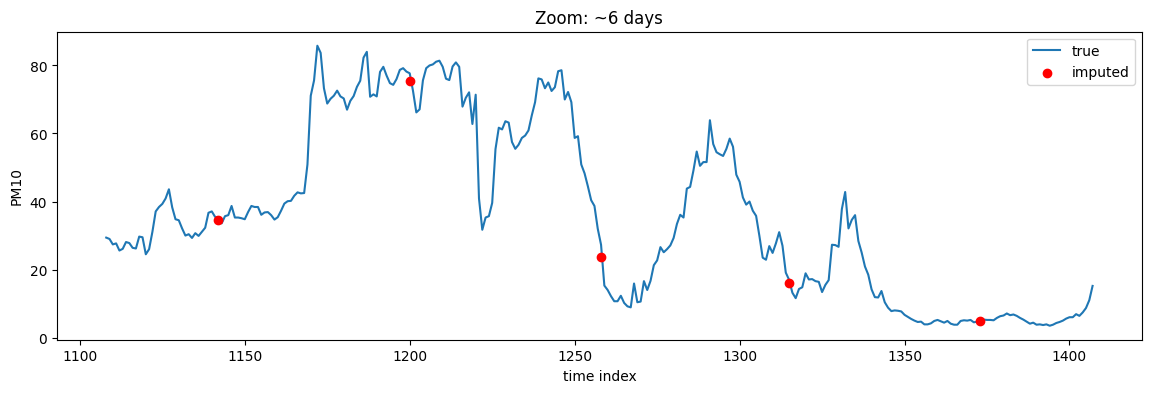

In [5]:
plt.figure(figsize=(14, 4))
plt.plot(df["pm10_true"].values, color="lightgray", linewidth=0.7, label="true time series")
plt.scatter(np.where(missing)[0], best[missing], color="red", s=8, label="imputed (linear)")
plt.ylim(0, 150)
plt.xlabel("time index (30 min steps)")
plt.ylabel("PM10 [µg/m³]")
plt.title("Time series with imputed values")
plt.legend()
plt.show()

# zoom into a few days to see details
start = np.where(missing)[0][20] - 150
plt.figure(figsize=(14, 4))
plt.plot(range(start, start + 300), df["pm10_true"][start:start + 300], label="true")
m = missing[start:start + 300]
plt.scatter(np.where(m)[0] + start, best[start:start + 300][m], color="red", zorder=3, label="imputed")
plt.xlabel("time index"); plt.ylabel("PM10"); plt.title("Zoom: ~6 days"); plt.legend()
plt.show()

➡ The imputed points are spread over the whole year and lie **on** the curve of the real series.
They do not create artificial peaks or gaps → the imputation will not harm the following analysis.

## Summary
| Question | Answer |
|---|---|
| best method | linear interpolation (expected, because PM10 changes slowly) |
| error high? | no – MAE ≈ 1.4 µg/m³ vs. mean ≈ 21 µg/m³; mean/std of series unchanged |
| error distribution | centred at 0, narrow, long tails; P(rel. error > 5 %) ≈ 42 % |
| plot | imputed points fit the series well |